# First Agent

In [ ]:
# Agent ?

# "자율형AI", "지능형 에이전트", "AI 에이전트"
# 명령을 내리면 단순히 대답만 하는 챗봇(AI 어시스턴트)과 달리, 사람이 목표만 입력하면 
# 스스로 생각(추론)하고, 계획을 세우며, 필요한 도구를 사용해 주도적으로 작업을 완료하는 소프트웨어 시스템

# import

In [1]:
import os
from langchain_openai.chat_models.base import ChatOpenAI
from langchain.messages import HumanMessage, SystemMessage, AIMessage
from pprint import pprint

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
llm = ChatOpenAI(model='gpt-4o-mini', temperature=0.1)

In [14]:
prompt = "Cost of $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12"

# 5273.38

In [15]:
print(llm.invoke(prompt).content)

To find the total cost, you can add all the amounts together:

\[
355.39 + 924.87 + 721.20 + 1940.29 + 573.63 + 65.72 + 35.00 + 552.00 + 76.16 + 29.12
\]

Calculating step by step:

1. \( 355.39 + 924.87 = 1280.26 \)
2. \( 1280.26 + 721.20 = 2001.46 \)
3. \( 2001.46 + 1940.29 = 3941.75 \)
4. \( 3941.75 + 573.63 = 4515.38 \)
5. \( 4515.38 + 65.72 = 4581.10 \)
6. \( 4581.10 + 35.00 = 4616.10 \)
7. \( 4616.10 + 552.00 = 5168.10 \)
8. \( 5168.10 + 76.16 = 5244.26 \)
9. \( 5244.26 + 29.12 = 5273.38 \)

So, the total cost is **$5273.38**.


In [ ]:
# 7.429560069262282e+23

In [ ]:
# ★LLM 은 산술연산을 할수 없다!!
# LLM은 '산술연산'을 수행하지 않습니다.  이런 계산은 AI보다 '계산기'가 더 잘한다!
# LLM 은 text 를 생성해내는 겁니다. 문장 시퀀스의 다음 token 이 무엇인지 통계적으로 추측하는 겁니다.

# 이러한 LLM 의 오류를 잡기위해선 agent 를 제공해주어야 한다.
# 그리고 agent 를 위한 tool(들) 을 만들고, agent 가 tool 을 선택해서 실행하는 것이다.

# Agent

In [ ]:
# 에이전트는 언어 모델과 도구를 결합하여 작업에 대해 추론하고, 사용할 도구를 결정하고, 
# 반복적으로 해결책을 찾아낼 수 있는 시스템

## create_agent()

Creates an agent graph that calls tools in a loop until a stopping condition is met.


- `create_agent` 실제 운영 환경에서 사용 가능한 에이전트 구현을 제공합니다.
- Creates an agent graph that calls tools in a loop until a stopping condition is met.

- `create_agent` 는 LangGraph를 사용하여 그래프 기반 에이전트 런타임을 구축합니다 . 
- 그래프는 에이전트가 정보를 처리하는 방식을 정의하는 노드(단계)와 엣지(연결)로 구성됩니다. 
- 에이전트는 이 그래프를 따라 이동하며 모델 노드(모델을 호출), 도구 노드(도구를 실행), 미들웨어와 같은 노드를 실행합니다.

- https://reference.langchain.com/python/langchain/agents/?h=create_agent#langchain.agents.create_agent

- https://docs.langchain.com/oss/python/langchain/agents




```python
create_agent(
    model: str | BaseChatModel,
    tools: Sequence[BaseTool | Callable[..., Any] | dict[str, Any]] | None = None,  # A list of tools, dict, or Callable.
    *,
    system_prompt: str | SystemMessage | None = None,
    middleware: Sequence[AgentMiddleware[StateT_co, ContextT]] = (),
    response_format: ResponseFormat[ResponseT]
    | type[ResponseT]
    | dict[str, Any]
    | None = None,
    state_schema: type[AgentState[ResponseT]] | None = None,
    context_schema: type[ContextT] | None = None,
    checkpointer: Checkpointer | None = None,
    store: BaseStore | None = None,
    interrupt_before: list[str] | None = None,
    interrupt_after: list[str] | None = None,
    debug: bool = False,
    name: str | None = None,
    cache: BaseCache[Any] | None = None,
) -> CompiledStateGraph[
    AgentState[ResponseT], ContextT, _InputAgentState, _OutputAgentState[ResponseT]
]
```

![](https://mintcdn.com/langchain-5e9cc07a/Tazq8zGc0yYUYrDl/oss/images/core_agent_loop.png?w=1100&fit=max&auto=format&n=Tazq8zGc0yYUYrDl&q=85&s=88bef556edba9869b759551c610c60f4)

In [16]:
from langchain.agents import create_agent

## tool 준비

In [17]:
# 함수로 준비
def plus(a, b):
    return a + b

# 위 파이썬 함수를 agent 가 실제로 사용할수 있는 tool 로 변환해서 전달해주어야 한다 
#  여기선 StructuredTool 을 사용해볼거다.

## StructuredTool

In [18]:
from langchain_core.tools.structured import StructuredTool

# 매개변수를 복수개(임의의 개수) 받는 tool.


In [19]:
agent = create_agent(
    model = ChatOpenAI(
        model='gpt-4o-mini',
        temperature=0.0,
    ),
    tools = [   # agent 내에서 사용할 tool(들)
        StructuredTool.from_function(
            func=plus,  # 함수를 전달 -> tool 변환
            name="SumCalculator",  # tool 이름 지정  (📌 tool이름에 공백 불가!)
            description="Use this to perform sum of two numbers. This tool take two arguments, both  should be numbers."
        ),
    ],
)

type(agent)  # CompiledStateGraph 객체

langgraph.graph.state.CompiledStateGraph

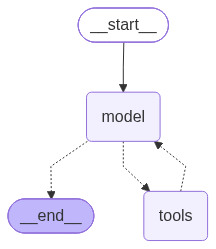

In [20]:
agent

### agent 호출
- agent 도 Runnable 객체 .  invoke() 있다.   chain 에서도 사용 가능.

In [21]:
result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Cost of $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12",
        }
    ],
})

result

{'messages': [HumanMessage(content='Cost of $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12', additional_kwargs={}, response_metadata={}, id='599e910c-7d57-4111-bc6a-417673fa6c6c'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 127, 'prompt_tokens': 114, 'total_tokens': 241, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_03cfc9828c', 'id': 'chatcmpl-EluSUYvl4jOemXoB73N0hNxr4DPdi', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f388-25da-7ad0-be5e-44b2b32d5f5d-0', tool_calls=[{'name': 'Su

In [22]:
type(result)

dict

In [23]:
result.keys()

dict_keys(['messages'])

In [24]:
len(result['messages'])

14

In [25]:
result['messages'][0]  # HumanMessage

HumanMessage(content='Cost of $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12', additional_kwargs={}, response_metadata={}, id='599e910c-7d57-4111-bc6a-417673fa6c6c')

In [26]:
result['messages'][1]  # AIMessage

# content='' 없다!
# tool_calls=[]  주목  tool 호출을 응답!
# 'finish_reason': 'tool_calls'

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 127, 'prompt_tokens': 114, 'total_tokens': 241, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_03cfc9828c', 'id': 'chatcmpl-EluSUYvl4jOemXoB73N0hNxr4DPdi', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f388-25da-7ad0-be5e-44b2b32d5f5d-0', tool_calls=[{'name': 'SumCalculator', 'args': {'a': 355.39, 'b': 924.87}, 'id': 'call_zY6qCC9wbjTIeB1K1LgDuRal', 'type': 'tool_call'}, {'name': 'SumCalculator', 'args': {'a': 721.2, 'b': 1940.29}, 'id': 'call_aEqRzN9fFch9aPIG1UgAxVz4', 'type': 'tool_call

In [27]:
# "Cost of $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12"
result['messages'][1].tool_calls

[{'name': 'SumCalculator',
  'args': {'a': 355.39, 'b': 924.87},
  'id': 'call_zY6qCC9wbjTIeB1K1LgDuRal',
  'type': 'tool_call'},
 {'name': 'SumCalculator',
  'args': {'a': 721.2, 'b': 1940.29},
  'id': 'call_aEqRzN9fFch9aPIG1UgAxVz4',
  'type': 'tool_call'},
 {'name': 'SumCalculator',
  'args': {'a': 573.63, 'b': 65.72},
  'id': 'call_1zX4iTn2MNxTmXFbj3mG2oA6',
  'type': 'tool_call'},
 {'name': 'SumCalculator',
  'args': {'a': 35.0, 'b': 552.0},
  'id': 'call_IVn81ADchOpX2fQyupqIjD3O',
  'type': 'tool_call'},
 {'name': 'SumCalculator',
  'args': {'a': 76.16, 'b': 29.12},
  'id': 'call_ZR9q1E0WoxeHU1r0vOikUxIO',
  'type': 'tool_call'}]

In [ ]:
# Agent 에서 위 5번의 tool 호출이 이루어진다
#  그 결과가! 다음 5번의 ToolMessage 에서 나온다!

In [28]:
result['messages'][2:7]  # plus() 함수가 호출되고 리턴한 값들.

[ToolMessage(content='1280.26', name='SumCalculator', id='20c2a807-b2f8-49f7-9db6-3b14229cc49b', tool_call_id='call_zY6qCC9wbjTIeB1K1LgDuRal'),
 ToolMessage(content='2661.49', name='SumCalculator', id='22fe104e-a35f-4dc9-938e-9c123f08de85', tool_call_id='call_aEqRzN9fFch9aPIG1UgAxVz4'),
 ToolMessage(content='639.35', name='SumCalculator', id='b085643f-b5c4-4aef-8c38-d223b564fb21', tool_call_id='call_1zX4iTn2MNxTmXFbj3mG2oA6'),
 ToolMessage(content='587.0', name='SumCalculator', id='13a5a34e-8b20-4950-9f11-959ca9df944c', tool_call_id='call_IVn81ADchOpX2fQyupqIjD3O'),
 ToolMessage(content='105.28', name='SumCalculator', id='f8d4aaba-fb92-47f6-b67c-7c23adc050b4', tool_call_id='call_ZR9q1E0WoxeHU1r0vOikUxIO')]

In [29]:
result['messages'][7]  # 다시 AIMessage

# 아직 task 가 끝나지 않음  'finish_reason': 'tool_calls'
# Agent 는 주어진 목표가 완수될때까지 계속 진행.

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 278, 'total_tokens': 302, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_03cfc9828c', 'id': 'chatcmpl-EluSXHHLZP522sB8kax1FmZTWu6Ny', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f388-3185-71f3-ab4d-99a364a9f0b3-0', tool_calls=[{'name': 'SumCalculator', 'args': {'a': 1280.26, 'b': 2661.49}, 'id': 'call_IkaOokRgaVzulFS5NjlAtuwf', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 278, 'output_tokens': 24, 'total_tokens': 302, 'input_token_de

In [30]:
result['messages'][7].tool_calls

[{'name': 'SumCalculator',
  'args': {'a': 1280.26, 'b': 2661.49},
  'id': 'call_IkaOokRgaVzulFS5NjlAtuwf',
  'type': 'tool_call'}]

In [31]:
result['messages'][8]

ToolMessage(content='3941.75', name='SumCalculator', id='3afbf14b-76c6-4493-92b3-3fdadc1d3cb7', tool_call_id='call_IkaOokRgaVzulFS5NjlAtuwf')

In [32]:
result['messages'][9]

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 314, 'total_tokens': 336, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_03cfc9828c', 'id': 'chatcmpl-EluSY2OUOZofZTgkhYyC7PUtg3psG', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f388-38ab-79b0-9484-eca124c3af71-0', tool_calls=[{'name': 'SumCalculator', 'args': {'a': 639.35, 'b': 587.0}, 'id': 'call_myoWnNII37lgo6oakzYevZKy', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 314, 'output_tokens': 22, 'total_tokens': 336, 'input_token_detai

In [33]:
result['messages'][9].tool_calls

[{'name': 'SumCalculator',
  'args': {'a': 639.35, 'b': 587.0},
  'id': 'call_myoWnNII37lgo6oakzYevZKy',
  'type': 'tool_call'}]

In [34]:
result['messages'][10]

ToolMessage(content='1226.35', name='SumCalculator', id='5f42e838-ef6e-40cc-ae5e-64ce1f879431', tool_call_id='call_myoWnNII37lgo6oakzYevZKy')

In [35]:
result['messages'][11]

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 348, 'total_tokens': 372, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_03cfc9828c', 'id': 'chatcmpl-EluSYQifCnWNlXBkTiGzYDuS2auxg', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1f388-3c9f-7de1-8cc3-d96dd11a2f51-0', tool_calls=[{'name': 'SumCalculator', 'args': {'a': 3941.75, 'b': 1226.35}, 'id': 'call_LEy6b14zksTds1Hr2NCTVYL8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens': 24, 'total_tokens': 372, 'input_token_de

In [36]:
result['messages'][11].tool_calls

[{'name': 'SumCalculator',
  'args': {'a': 3941.75, 'b': 1226.35},
  'id': 'call_LEy6b14zksTds1Hr2NCTVYL8',
  'type': 'tool_call'}]

In [37]:
result['messages'][12]

ToolMessage(content='5168.1', name='SumCalculator', id='69c1c234-16ec-4364-818a-a100d4106c1c', tool_call_id='call_LEy6b14zksTds1Hr2NCTVYL8')

In [38]:
result['messages'][13]

# 'finish_reason': 'stop'   <-  Agent 종료. 목표 달성!

AIMessage(content='The total cost is $5168.10.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 384, 'total_tokens': 395, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_03cfc9828c', 'id': 'chatcmpl-EluSZYQpvdi5LJtfgEZEmoQBFcseY', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1f388-3fe9-7fa0-8777-afe79b269d0c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 384, 'output_tokens': 11, 'total_tokens': 395, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

### 최종결과는!

In [39]:
result['messages'][-1].content

'The total cost is $5168.10.'

In [ ]:
"""
       $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12
         └─────┬─────┘       └─────┬─────┘     └─────┬─────┘         └─────┬─────┘     └─────┬─────┘
결과        1280.26              2661.49           639.35                587              105.28

                     └─────┬─────┘ 
                        3941.75

                                                        └─────┬─────┘ 
                                                            1226.35

                                         └─────┬─────┘
                                           5168.10  (💥오답)

# 정답은 5273.38 <- 이게 나와야 하는데
"""
None

## 해결: 도구 함수의 기본값, typehint

In [ ]:
# b에 기본값을 주면 됩니다. StructuredTool.from_function은 
# 내부적으로 함수 시그니처(타입힌트 + 기본값)를 보고 pydantic 스키마를 만들기 때문에, 
# 기본값이 있는 파라미터는 자동으로 optional 필드가 되어 LLM이 생략해도 됩니다. 
# 생략 시에는 Python이 기본값(0)을 채워서 함수가 호출됩니다.

In [41]:
def plus(a: float, b: float = 0) -> float:
    """두 수를 더한다. b가 없으면 0으로 처리."""
    return a + b    

agent = create_agent(
    model = ChatOpenAI(temperature=0.0, model='gpt-4o'),
    tools = [  # tool(들) 전달
        StructuredTool.from_function(
            func=plus,   # 함수를 전달 -> tool 변환
            name="SumCalculator",  # tool 이름 지정 (📌 공백불가)
            description=(
                "Use this tool to sum two numbers. The second number (b) is optional "
                "and defaults to 0 if not provided — so calling it with only one number "
                "simply returns that number."
            )
        ),
    ]
)
    
result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Cost of $355.39 + $924.87 + $721.2 + $1940.29 + $573.63 + $65.72 + $35.00 + $552.00 + $76.16 + $29.12",
        }
    ],
})

result['messages'][-1].content

'The total cost is $5273.38.'